In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import scipy as sp
from scipy.optimize import minimize

np.random.seed(5)

In [2]:
# Set Tickers for the portfolio and number of assets

tickers = ["AAPL", "AMZN", "JPM", "XOM", "JNJ", "PG", "CAT", "NEE", "EFA", "EEM", "VNQ", "GLD", "DBC", "TLT", "LQD"]

n_assets = len(tickers)

# Set Risk Free rate
risk_free_rate = 0.04     # UK 3-month treasury bill

In [3]:
# Set training and test periods then pull asset data from yfinance

train_start = "2019-01-01"
train_end = "2023-12-31"
test_start = "2024-01-01"
test_end = "2026-06-30"

# Training period will include 2019 to 2023 while test period will be from 2024 to present

training_data = yf.download(tickers, start = train_start, end = train_end)
test_data = yf.download(tickers, start = test_start, end = test_end)

# Set the data to be used for calculations 

stock_data = training_data

[*********************100%***********************]  15 of 15 completed
[*********************100%***********************]  15 of 15 completed


In [4]:
# Generate random weightings using a dirichlet distribution
# Generate alpha and n_weighting_sims
n_weighting_sims = 50000
alpha = np.ones(n_assets)

# Generate weightings

portfolio_weightings = np.random.dirichlet(alpha, size = (n_weighting_sims))

# Portfolio Sharpe Ratios

## Asset and Portfolio Returns

In [5]:
# Create array to store log returns for each day 
daily_log_returns = np.zeros(shape = (n_assets, len(stock_data) - 1), dtype = float)

# Calculate log returns for each asset
for i in range (n_assets):
    asset = tickers[i]
    daily_log_returns[i] = np.log(stock_data["Close"][asset] / stock_data["Close"][asset].shift(1)).dropna()

In [6]:
# Annualised voaltility and returns for each asset

annualised_returns = np.zeros(n_assets, dtype = float)
annualised_volatility = np.zeros(n_assets, dtype = float)

annualised_returns = np.mean(daily_log_returns, axis = 1) * 252
asset_annualised_volatility = np.std(daily_log_returns, axis = 1) * np.sqrt(252)

In [7]:
# Portfolio returns

weighted_returns = np.zeros(shape = (n_weighting_sims, n_assets), dtype = float)
weighted_returns = portfolio_weightings * annualised_returns
portfolio_returns = np.sum(weighted_returns, axis = 1)

## Asset and Portfolio Volatilities

In [8]:
# Create Covariance matrix for the assets using daily log returns
asset_covariance_matrix = np.cov(daily_log_returns)

# Annualise cov matrix
asset_covariance_matrix_annualised = asset_covariance_matrix * 252

In [9]:
# Use dot multiplication with portfolio weightings and covariance 
weighted_covariance = portfolio_weightings @ asset_covariance_matrix_annualised

# Calculate portfolio variances before taking sqrt for volatility seeing they were annualised during the cov matrix
portfolio_variance = np.sum(weighted_covariance * portfolio_weightings, axis = 1)
portfolio_volatility = np.sqrt(portfolio_variance)

## Portfolio Sharpe Ratios

In [10]:
portfolio_sharpe_ratios = (portfolio_returns - risk_free_rate) / portfolio_volatility

In [11]:
max_sharpe_portfolio = np.argmax(portfolio_sharpe_ratios)
mc_max_sharpe_weights = portfolio_weightings[max_sharpe_portfolio]

min_volatility_portfolio = np.argmin(portfolio_volatility)
mc_min_volatility_weightings = portfolio_weightings[min_volatility_portfolio]

### Highest Sharpe Ratio Portfolio

In [12]:
# Print the sharpe ratio of the portfolio with the highest sharpe ratio as well as the expected return, volatility and weights of that portfolio
print("Highest Sharpe Ratio Portfolio")
print(f"Sharpe ratio: {portfolio_sharpe_ratios.max():.4f}")
print(f"Expected Return: {portfolio_returns[max_sharpe_portfolio]*100:.2f}%")
print(f"Portfolio Volatility: {portfolio_volatility[max_sharpe_portfolio]*100:.2f}%")

weights_df = pd.DataFrame({
    "Ticker": tickers,
    "Weight (%)": mc_max_sharpe_weights*100
})

display(weights_df.round(2))

Highest Sharpe Ratio Portfolio
Sharpe ratio: 0.8233
Expected Return: 21.43%
Portfolio Volatility: 21.17%


,Ticker,Weight (%)
0,AAPL,53.66
1,AMZN,2.37
2,JPM,1.84
3,XOM,2.84
4,JNJ,0.37
5,PG,0.68
6,CAT,1.31
7,NEE,5.02
8,EFA,0.90
9,EEM,0.47


### Minimum Volatility Portfolio

In [13]:
# Print the sharpe ratio of the portfolio with the lowest volatility as well as the expected return, volatility and weights of that portfolio
print("Minimum Volatility Portfolio")
print(f"Sharpe ratio: {portfolio_sharpe_ratios[min_volatility_portfolio]:.4f}")
print(f"Expected Return: {portfolio_returns[min_volatility_portfolio]*100:.2f}%")
print(f"Portfolio Volatility: {portfolio_volatility[min_volatility_portfolio]*100:.2f}%")

weights_df = pd.DataFrame({
    "Ticker": tickers,
    "Weight (%)": mc_min_volatility_weightings*100
})

display(weights_df.round(2))

Minimum Volatility Portfolio
Sharpe ratio: 0.1586
Expected Return: 5.57%
Portfolio Volatility: 9.89%


,Ticker,Weight (%)
0,AAPL,1.88
1,AMZN,2.61
2,JPM,2.10
3,XOM,1.97
4,JNJ,9.61
5,PG,5.29
6,CAT,2.93
7,NEE,2.59
8,EFA,5.35
9,EEM,0.79


### Monte Carlo Portfolio Visualisation

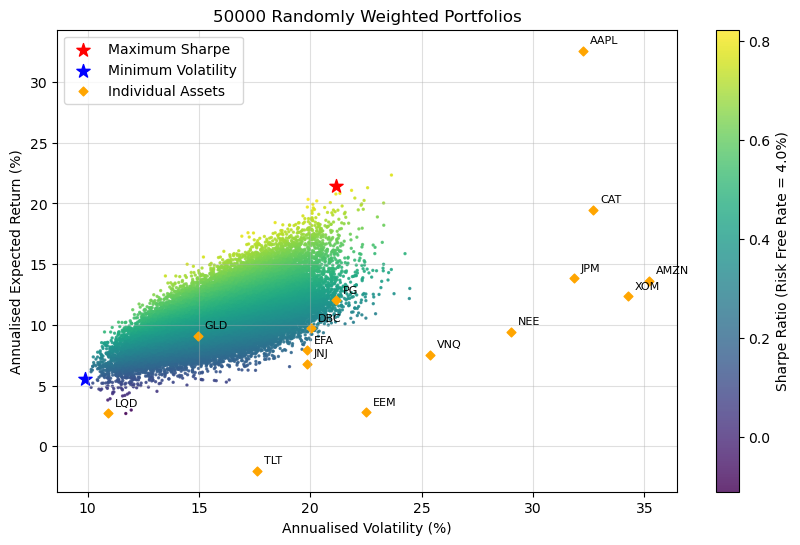

In [14]:
plt.figure(figsize = (10, 6))
plt.scatter(portfolio_volatility*100, portfolio_returns*100, alpha = 0.8, s = 2, c = portfolio_sharpe_ratios, cmap = "viridis")
plt.colorbar(label = f"Sharpe Ratio (Risk Free Rate = {risk_free_rate * 100}%)")
plt.ylabel("Annualised Expected Return (%)")
plt.xlabel("Annualised Volatility (%)")
plt.title(f"{n_weighting_sims} Randomly Weighted Portfolios")

plt.scatter(portfolio_volatility[max_sharpe_portfolio]*100, portfolio_returns[max_sharpe_portfolio]*100,
            color = "red", marker = "*", label = "Maximum Sharpe", s = 100)

plt.scatter(portfolio_volatility[min_volatility_portfolio]*100, portfolio_returns[min_volatility_portfolio]*100,
            color = "blue", marker = "*", label = "Minimum Volatility", s = 100)

plt.scatter(asset_annualised_volatility*100, annualised_returns*100,
            color = "orange", marker = "D", label = "Individual Assets", s = 20)

for i, ticker in enumerate(tickers):
    plt.annotate(ticker,
                 (asset_annualised_volatility[i]*100, annualised_returns[i]*100),
                 textcoords="offset points", xytext=(5, 5), fontsize=8)

plt.grid(alpha = 0.4)
plt.legend()
plt.show()

# Portfolio Optimisation using Scipy

The next step of the project aims to find the optimal portfolio weightings using Scipy's minimize function. It will find the weightings for the optimal porfolio with the lowest risk as well as the portfolio with the highest sharpe ratio. Finally, we can plot the portfolio efficent frontier minimizing the risk at given levels of return ie finding the "best" portfolio when targeting a given return. I will first find the unconstrained portfolios before finding the constrained portfolios where there will be a cap on how much of an individual asset can be held and assets can no longer be shorted.

## Unconstrained Optimisation

### Portfolio Statstics

In [15]:
# Create a function to output portfolio expected stats (Returns, Volatility, Sharpe Ratio) for when optimal weights are found

def portfolio_stats(optimised_weights):
    
    optimised_weights = np.array(optimised_weights)
    optimised_returns = np.sum(annualised_returns * optimised_weights)
    
    optimised_weighted_covariance = optimised_weights @ asset_covariance_matrix_annualised
    optimised_volatility = np.sqrt(np.sum(optimised_weighted_covariance * optimised_weights))

    optimised_sharpe = (optimised_returns - risk_free_rate) / optimised_volatility

    return {"Return": optimised_returns, "Volatility": optimised_volatility, "Sharpe ratio": optimised_sharpe}

def portfolio_stats_tidy(optimised_weights):
    return (f"Annualised Return: {portfolio_stats(optimised_weights)["Return"]*100:.2f}%\n"
            f"Annualised Volatility: {portfolio_stats(optimised_weights)["Volatility"]*100:.2f}%\n"
            f"Sharpe ratio: {portfolio_stats(optimised_weights)["Sharpe ratio"]:.4f}")

### Minimization Functions
Create functions that can be used with Minimize from scipy in order to maximise these metrics including: Sharpe Ratio, Volatility (aim to minimise) and Returns.

In [16]:
# Use the negative for sharpe ratio as Scipy doesnt have a maximise function so instead look to minimize a negative function
def maximise_sharpe(optimised_weights):
    return - portfolio_stats(optimised_weights)["Sharpe ratio"]

# We dont make volatility negative as we want the smallest volatility ie we acutally want to minimize volatility instead of maximise
def minimize_volatility(optimised_weights):
    return portfolio_stats(optimised_weights)["Volatility"]

# Make returns negative in order to maximise
def maximise_return(optimised_weights):
    return - portfolio_stats(optimised_weights)["Return"]

### Remaining Parameters
The minimize function also requires constraints, bounds and an initial guess. 

In [17]:
# In the unconstrained optimizations the only constraint is that the weights equal 1 ie all money is invested. Shorting is also allowed

# Set the cosntraint that sum of weights equals 1
constraints = ({'type' : 'eq', 'fun': lambda x: np.sum(x) -1})

# Set the bounds allowing shorting up to 15% per asset 
bounds = [(0, 1)] * n_assets

# Set intiial guess where the weights for all assets is equal

initial_guess = n_assets * [1 / n_assets]

### Maximum Sharpe Portfolio (Unconstrained)

In [18]:
unconstrained_max_sharpe = minimize(maximise_sharpe,
                                    initial_guess,
                                    method = "SLSQP",
                                    bounds = bounds,
                                    constraints = constraints)

unconstrained_max_sharpe_stats = portfolio_stats(optimised_weights = unconstrained_max_sharpe["x"])
unconstrained_max_sharpe_weights = unconstrained_max_sharpe["x"]

In [19]:
print("Unconstrained Optimal Sharpe Ratio Portfolio")
print(portfolio_stats_tidy(optimised_weights = unconstrained_max_sharpe["x"]))
weights_df = pd.DataFrame({
    "Ticker": tickers,
    "Weight (%)": unconstrained_max_sharpe["x"]*100
})

display(weights_df.round(2))

Unconstrained Optimal Sharpe Ratio Portfolio
Annualised Return: 22.37%
Annualised Volatility: 19.62%
Sharpe ratio: 0.9364


,Ticker,Weight (%)
0,AAPL,52.18
1,AMZN,0.00
2,JPM,0.00
3,XOM,0.00
4,JNJ,0.00
5,PG,0.00
6,CAT,9.75
7,NEE,0.00
8,EFA,0.00
9,EEM,0.00


### Minimum Volatility Portfolio (Unconstrained)

In [20]:
unconstrained_min_volatility = minimize(minimize_volatility,
                                    initial_guess,
                                    method = "SLSQP",
                                    bounds = bounds,
                                    constraints = constraints)

unconstrained_min_volatility_stats = portfolio_stats(optimised_weights = unconstrained_min_volatility["x"])
unconstrained_min_vol_weights = unconstrained_min_volatility["x"]

In [21]:
print("Unconstrained Optimised Minimum Volatility Portfolio")
print(portfolio_stats_tidy(optimised_weights = unconstrained_min_volatility["x"]))
weights_df = pd.DataFrame({
    "Ticker": tickers,
    "Weight (%)": unconstrained_min_volatility["x"]*100
})

display(weights_df.round(2))

Unconstrained Optimised Minimum Volatility Portfolio
Annualised Return: 5.06%
Annualised Volatility: 9.01%
Sharpe ratio: 0.1175


,Ticker,Weight (%)
0,AAPL,0.00
1,AMZN,0.00
2,JPM,0.23
3,XOM,0.00
4,JNJ,14.33
5,PG,3.58
6,CAT,0.81
7,NEE,0.00
8,EFA,0.00
9,EEM,0.00


### Optimised Portfolio Visualisation

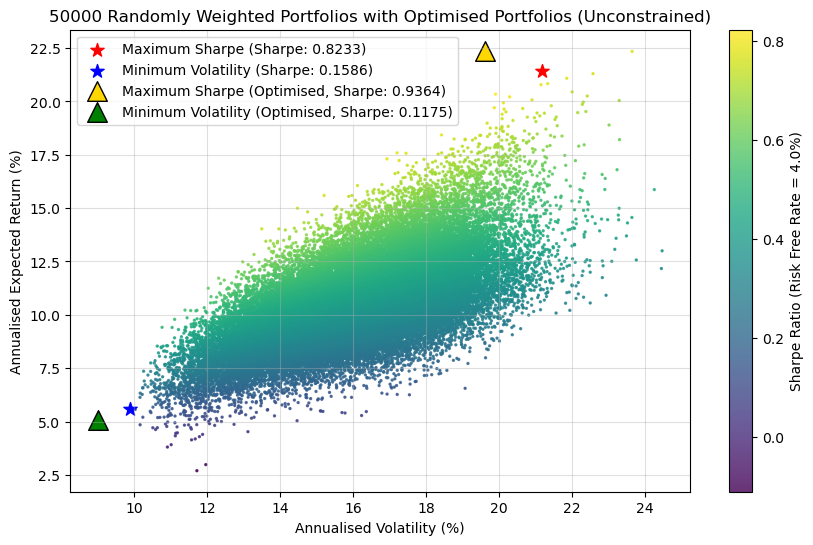

In [22]:
plt.figure(figsize = (10, 6))
plt.scatter(portfolio_volatility*100, portfolio_returns*100, alpha = 0.8, s = 2, c = portfolio_sharpe_ratios, cmap = "viridis")
plt.colorbar(label = f"Sharpe Ratio (Risk Free Rate = {risk_free_rate * 100}%)")
plt.ylabel("Annualised Expected Return (%)")
plt.xlabel("Annualised Volatility (%)")
plt.title(f"{n_weighting_sims} Randomly Weighted Portfolios with Optimised Portfolios (Unconstrained)")

plt.scatter(portfolio_volatility[max_sharpe_portfolio]*100, portfolio_returns[max_sharpe_portfolio]*100,
            color = "red", marker = "*", label = f"Maximum Sharpe (Sharpe: {portfolio_sharpe_ratios[max_sharpe_portfolio]:.4f})", s = 100)

plt.scatter(portfolio_volatility[min_volatility_portfolio]*100, portfolio_returns[min_volatility_portfolio]*100,
            color = "blue", marker = "*", label = f"Minimum Volatility (Sharpe: {portfolio_sharpe_ratios[min_volatility_portfolio]:.4f})", s = 100)

plt.scatter(unconstrained_max_sharpe_stats["Volatility"]*100, unconstrained_max_sharpe_stats["Return"]*100,
            color = "gold", edgecolors = "black", marker = "^", label = f"Maximum Sharpe (Optimised, Sharpe: {unconstrained_max_sharpe_stats["Sharpe ratio"]:.4f})", s = 200)

plt.scatter(unconstrained_min_volatility_stats["Volatility"]*100, unconstrained_min_volatility_stats["Return"]*100,
            color = "green", edgecolors = "black", marker = "^", label = f"Minimum Volatility (Optimised, Sharpe: {unconstrained_min_volatility_stats["Sharpe ratio"]:.4f})", s = 200)

plt.grid(alpha = 0.4)
plt.legend()
plt.show()

As expected the optimised portfolios noticeably outperform the previos best performing portfolios from the monte carlo simulation.

## Unconstrained Efficient Frontier
The final step for unconstrained optimisation is to plot the efficient frontier which shows the best performing (in terms of returns) portfolio for a given volatility.

In [23]:
# Set target returns according to max and min observed by monte carlo simualtion 
# so the minimize function can aim for the target return and minimise the volatility at each return

unconstrained_target_returns = np.linspace(np.min(portfolio_returns), np.max(portfolio_returns), 100)
unconstrained_efficient_frontier_volatility = []

# Re-define paramters and add a new constraint as the target return within a loop to pass in target returns

for target_return in (unconstrained_target_returns):


# Set the cosntraint that sum of weights equals 1
    constraints = ({'type':'eq','fun': lambda x: portfolio_stats(x)['Return']-target_return},
               {'type':'eq','fun': lambda x: np.sum(x)-1})

# Set the bounds no longer allowing shorting but no limit on a single asset
    bounds = [(0, 1)] * n_assets

# Set intiial guess where the weights for all assets is equal

    initial_guess = n_assets * [1 / n_assets]

# Find minimum volatility for each target return
    unconstrained_efficient_frontier = minimize(minimize_volatility,
                                            initial_guess,
                                            method = "SLSQP",
                                            constraints = constraints,
                                            bounds = bounds)

    unconstrained_efficient_frontier_volatility.append(unconstrained_efficient_frontier["fun"])

unconstrained_efficient_frontier_volatility = np.array(unconstrained_efficient_frontier_volatility)
unconstrained_efficient_frontier_sharpe = (unconstrained_target_returns - risk_free_rate) / unconstrained_efficient_frontier_volatility

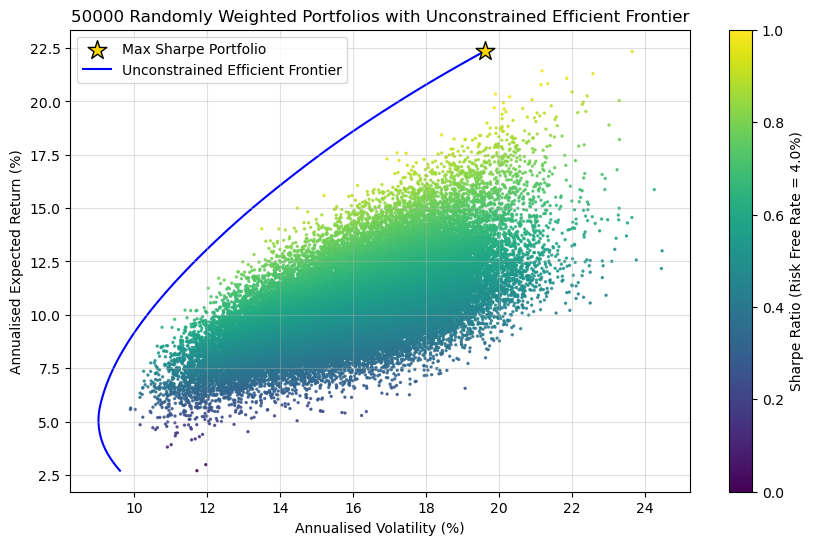

In [24]:
plt.figure(figsize = (10, 6))
plt.scatter(portfolio_volatility*100, portfolio_returns*100, alpha = 0.8, s = 2, c = portfolio_sharpe_ratios, cmap = "viridis")
plt.ylabel("Annualised Expected Return (%)")
plt.xlabel("Annualised Volatility (%)")
plt.title(f"{n_weighting_sims} Randomly Weighted Portfolios with Unconstrained Efficient Frontier")

# Plot max sharpe portfolio
plt.scatter(unconstrained_max_sharpe_stats["Volatility"]*100, unconstrained_max_sharpe_stats["Return"]*100,
           marker = "*", color = "gold", s = 200, edgecolors = "black", label = "Max Sharpe Portfolio", zorder = 10)

# Plot efficient frontier
plt.plot(unconstrained_efficient_frontier_volatility*100, unconstrained_target_returns*100,
         color = "blue", zorder = 1, label = "Unconstrained Efficient Frontier")
           
plt.colorbar(label = f"Sharpe Ratio (Risk Free Rate = {risk_free_rate * 100}%)")

plt.legend()
plt.grid(alpha = 0.4)
plt.show()

## Constrained Optimisation
The next step is to once again find the same optimal portfolios and efficient frontier but with an added constraint preventing shorting any asset and also preventing holding more than 15% in one asset.

### Portfolio Statistics
Define the portfolio statistics again to be used for the minimization as well as the tidy presentation for showing results

In [25]:
# Create a function to output portfolio expected stats (Returns, Volatility, Sharpe Ratio) for when optimal weights are found

def portfolio_stats(optimised_weights):
    
    optimised_weights = np.array(optimised_weights)
    optimised_returns = np.sum(annualised_returns * optimised_weights)
    
    optimised_weighted_covariance = optimised_weights @ asset_covariance_matrix_annualised
    optimised_volatility = np.sqrt(np.sum(optimised_weighted_covariance * optimised_weights))

    optimised_sharpe = (optimised_returns - risk_free_rate) / optimised_volatility

    return {"Return": optimised_returns, "Volatility": optimised_volatility, "Sharpe ratio": optimised_sharpe}

def portfolio_stats_tidy(optimised_weights):
    return (f"Return: {portfolio_stats(optimised_weights)["Return"]*100:.2f}%\n"
            f"Volatility: {portfolio_stats(optimised_weights)["Volatility"]*100:.2f}%\n"
            f"Sharpe ratio: {portfolio_stats(optimised_weights)["Sharpe ratio"]:.4f}")

### Minimization functions
Once again define the same functions for Scipy to minimize

In [26]:
# Use the negative for sharpe ratio as Scipy doesnt have a maximise function so instead look to minimize a negative function
def maximise_sharpe(optimised_weights):
    return - portfolio_stats(optimised_weights)["Sharpe ratio"]

# We dont make volatility negative as we want the smallest volatility ie we acutally want to minimize volatility instead of maximise
def minimize_volatility(optimised_weights):
    return portfolio_stats(optimised_weights)["Volatility"]

# Make returns negative in order to maximise
def maximise_return(optimised_weights):
    return - portfolio_stats(optimised_weights)["Return"]

### Remaining Parameters
Once again we need to define the constraints and initial guess. We also need to define the bounds again. The bounds will be slightly different for the constrained optimsiation where shorting isnt allowed and there will be a 15% cap on individual assets.

In [27]:
# In the constrained optimisation, weightings must still sum to 1, however the bounds now change to enforce the no shorting and 15% cap rules

# Set the cosntraint that sum of weights equals 1
constraints = ({'type' : 'eq', 'fun': lambda x: np.sum(x) -1})

# Set the bounds which prevent shorting and also cap individual assets to 15% of the total portfolio
bounds = [(0, 0.15)] * n_assets

# Set intiial guess where the weights for all assets is equal

initial_guess = n_assets * [1 / n_assets]

### Maximum Sharpe Portfolio (Constrained)

In [28]:
constrained_max_sharpe = minimize(maximise_sharpe,
                                  initial_guess,
                                  method = "SLSQP",
                                  constraints = constraints,
                                  bounds = bounds)

constrained_max_sharpe_stats = portfolio_stats(optimised_weights = constrained_max_sharpe["x"])
constrained_max_sharpe_weights = constrained_max_sharpe["x"]

In [29]:
print("Constrained Optimised Sharpe Ratio Portfolio")
print(portfolio_stats_tidy(optimised_weights = constrained_max_sharpe["x"]))
weights_df = pd.DataFrame({
    "Ticker": tickers,
    "Weight (%)": constrained_max_sharpe["x"]*100
})

display(weights_df.round(2))

Constrained Optimised Sharpe Ratio Portfolio
Return: 13.96%
Volatility: 14.13%
Sharpe ratio: 0.7052


,Ticker,Weight (%)
0,AAPL,15.00
1,AMZN,4.32
2,JPM,2.46
3,XOM,0.00
4,JNJ,2.84
5,PG,15.00
6,CAT,15.00
7,NEE,0.00
8,EFA,0.00
9,EEM,0.00


### Minimum Volatility Portfolio (Constrained)

In [30]:
constrained_min_volatility = minimize(minimize_volatility,
                                      initial_guess,
                                      method = "SLSQP",
                                      constraints = constraints,
                                      bounds = bounds)

constrained_min_volatility_stats = portfolio_stats(optimised_weights = constrained_min_volatility["x"])
constrained_min_vol_weights = constrained_min_volatility["x"]

In [31]:
print("Constrained Optimised Minimum Volatility Portfolio")
print(portfolio_stats_tidy(optimised_weights = constrained_min_volatility["x"]))
weights_df = pd.DataFrame({
    "Ticker": tickers,
    "Weight (%)": constrained_min_volatility["x"]*100
})

display(weights_df.round(2))

Constrained Optimised Minimum Volatility Portfolio
Return: 6.26%
Volatility: 9.82%
Sharpe ratio: 0.2297


,Ticker,Weight (%)
0,AAPL,0.00
1,AMZN,0.00
2,JPM,0.00
3,XOM,0.00
4,JNJ,15.00
5,PG,13.29
6,CAT,0.33
7,NEE,0.00
8,EFA,6.18
9,EEM,5.19


### Constrained Optimal Portfolio Visualisation

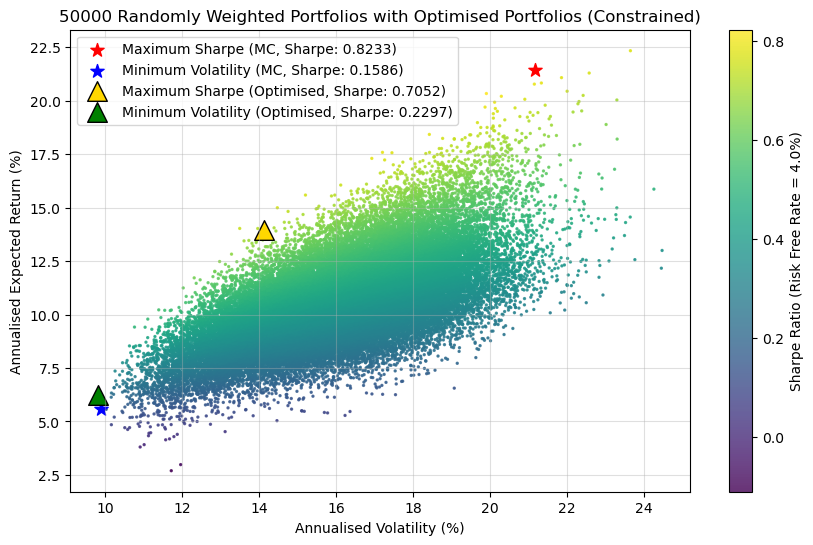

In [32]:
plt.figure(figsize = (10, 6))
plt.scatter(portfolio_volatility*100, portfolio_returns*100, alpha = 0.8, s = 2, c = portfolio_sharpe_ratios, cmap = "viridis")
plt.colorbar(label = f"Sharpe Ratio (Risk Free Rate = {risk_free_rate * 100}%)")
plt.ylabel("Annualised Expected Return (%)")
plt.xlabel("Annualised Volatility (%)")
plt.title(f"{n_weighting_sims} Randomly Weighted Portfolios with Optimised Portfolios (Constrained)")

plt.scatter(portfolio_volatility[max_sharpe_portfolio]*100, portfolio_returns[max_sharpe_portfolio]*100,
            color = "red", marker = "*", label = f"Maximum Sharpe (MC, Sharpe: {portfolio_sharpe_ratios[max_sharpe_portfolio]:.4f})", s = 100)

plt.scatter(portfolio_volatility[min_volatility_portfolio]*100, portfolio_returns[min_volatility_portfolio]*100,
            color = "blue", marker = "*", label = f"Minimum Volatility (MC, Sharpe: {portfolio_sharpe_ratios[min_volatility_portfolio]:.4f})", s = 100)

plt.scatter(constrained_max_sharpe_stats["Volatility"]*100, constrained_max_sharpe_stats["Return"]*100,
            color = "gold", edgecolors = "black", marker = "^", label = f"Maximum Sharpe (Optimised, Sharpe: {constrained_max_sharpe_stats["Sharpe ratio"]:.4f})", s = 200)

plt.scatter(constrained_min_volatility_stats["Volatility"]*100, constrained_min_volatility_stats["Return"]*100,
            color = "green", edgecolors = "black", marker = "^", label = f"Minimum Volatility (Optimised, Sharpe: {constrained_min_volatility_stats["Sharpe ratio"]:.4f})", s = 200)

plt.grid(alpha = 0.4)
plt.legend()
plt.show()

When adding the additional constraints which prevent shorting and also capping an individual asset at 15% the optimal portfolios cant take such extreme positions causing the constrained optimal portfolios to fall much closer to the monte carlo simulated portfolios unlike the unconstrained optimised portfolios which took extreme positions. A comparison between constrained optimisation and unconstrained optimisation will follow later.

## Constrained Efficient Frontier
The final step for the constrained portfolios is to find the new efficient frontier before comparing the constrained and unconstrained optimum portfolios.

When adding the new constraints, so levels of returns achieved by the unconstrained monte carlo simulations become infeasible. This results in the efficient frontier showing straight lines at the top. The straight line at the bottom occurs because after the additonal constraints are added the minmize can no longer achive a lower volatility. Therefore we use the code below to set the target returns between a range that is achievable by minimize under the new constraints of no shorting and a 15% cap on individual assets.

In [33]:
from scipy.optimize import linprog

res_max = linprog(-annualised_returns,
                  A_eq=np.ones((1, n_assets)), b_eq=[1],
                  bounds=bounds)
max_return = -res_max.fun

min_var_return = portfolio_returns[np.argmin(portfolio_volatility)]
constrained_target_returns = np.linspace(min_var_return, max_return - 0.002, 80)

In [34]:

constrained_efficient_frontier_volatility = []

# Re-define paramters and add a new constraint as the target return within a loop to pass in target returns

for target_return in (constrained_target_returns):


# Set the cosntraint that sum of weights equals 1
    constraints = ({'type':'eq','fun': lambda x: portfolio_stats(x)['Return']-target_return},
               {'type':'eq','fun': lambda x: np.sum(x)-1})

# Set the bounds so they dont allow shorting so lower bound is 0 and there cant be more than 15% invested in one asset therefore 0.15 upper bound
    bounds = [(0, 0.15)] * n_assets

# Set intiial guess where the weights for all assets is equal

    initial_guess = n_assets * [1 / n_assets]

# Find minimum volatility for each target return
    constrained_efficient_frontier = minimize(minimize_volatility,
                                            initial_guess,
                                            method = "SLSQP",
                                            constraints = constraints,
                                            bounds = bounds)

    constrained_efficient_frontier_volatility.append(constrained_efficient_frontier["fun"])

constrained_efficient_frontier_volatility = np.array(constrained_efficient_frontier_volatility)
constrained_efficient_frontier_sharpe = (constrained_target_returns - risk_free_rate) / constrained_efficient_frontier_volatility

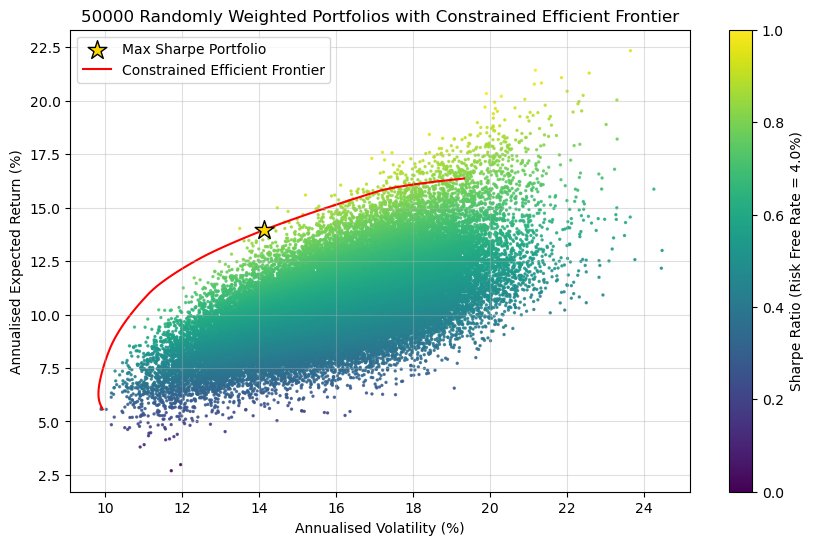

In [35]:
plt.figure(figsize = (10, 6))
plt.scatter(portfolio_volatility*100, portfolio_returns*100, alpha = 0.8, s = 2, c = portfolio_sharpe_ratios, cmap = "viridis")
plt.ylabel("Annualised Expected Return (%)")
plt.xlabel("Annualised Volatility (%)")
plt.title(f"{n_weighting_sims} Randomly Weighted Portfolios with Constrained Efficient Frontier")

# Plot max sharpe portfolio
plt.scatter(constrained_max_sharpe_stats["Volatility"]*100, constrained_max_sharpe_stats["Return"]*100,
            marker = "*", color = "gold", s = 200, label = "Max Sharpe Portfolio", edgecolors = "black", zorder = 10)

# Plot efficient frontier
plt.plot(constrained_efficient_frontier_volatility*100, constrained_target_returns*100, 
         color = "red", linewidth = 1.5, label = "Constrained Efficient Frontier", zorder = 1)
plt.colorbar(label = f"Sharpe Ratio (Risk Free Rate = {risk_free_rate * 100}%)")

plt.grid(alpha = 0.4)
plt.legend()
plt.show()

As expected after the constraints including preventing shorting and adding a 15% cap on individual assets are added, the achievable returns fall. While the efficient frontier out performs the monte carlo at lower levels of volatility and returns, once returns start to rise the constraints prevent enough risk being taken to achieve the higher levels of return that the monte carlo simulations managed to achieve.

## Capital Market Line
The efficient frontier shows all the optimal set of risky portfolios. However the capital market line (CML) adds a risk free asset and shows the further possible portoflios that investors can hold combining risky assets with the risk free asset. The tangency portfolio will also be the maximum sharpe ratio portfolio

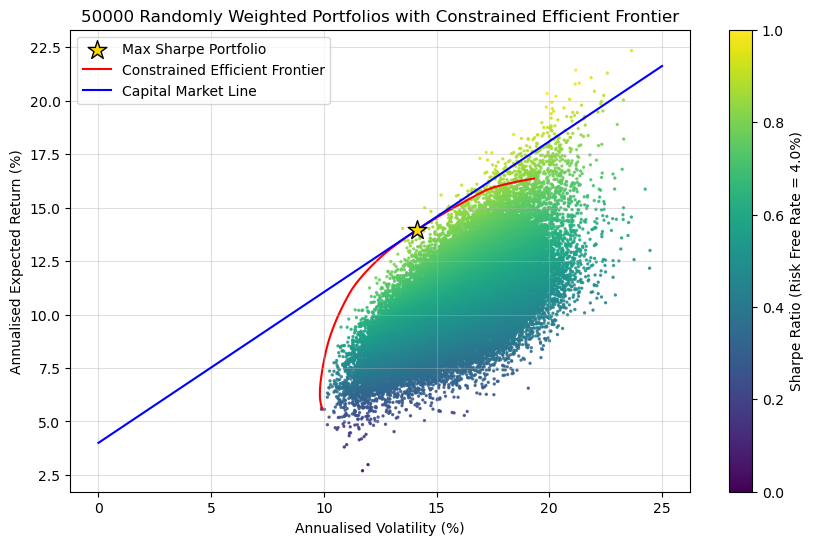

In [36]:
# Create volatility values to use to plot the CML then plot the graph with the CML

cml_volatilities = np.linspace(0, 25, 100)

plt.figure(figsize = (10, 6))
plt.scatter(portfolio_volatility*100, portfolio_returns*100, alpha = 0.8, s = 2, c = portfolio_sharpe_ratios, cmap = "viridis")
plt.ylabel("Annualised Expected Return (%)")
plt.xlabel("Annualised Volatility (%)")
plt.title(f"{n_weighting_sims} Randomly Weighted Portfolios with Constrained Efficient Frontier")

# Plot max sharpe portfolio
plt.scatter(constrained_max_sharpe_stats["Volatility"]*100, constrained_max_sharpe_stats["Return"]*100,
            marker = "*", color = "gold", s = 200, label = "Max Sharpe Portfolio", edgecolors = "black", zorder = 10)

# Plot efficient frontier
plt.plot(constrained_efficient_frontier_volatility*100, constrained_target_returns*100, 
         color = "red", linewidth = 1.5, label = "Constrained Efficient Frontier", zorder = 1)
plt.colorbar(label = f"Sharpe Ratio (Risk Free Rate = {risk_free_rate * 100}%)")

# Plot CML
plt.plot(cml_volatilities, risk_free_rate*100 + (cml_volatilities * constrained_max_sharpe_stats["Sharpe ratio"]), color = "blue", zorder = 5, label = "Capital Market Line")

plt.grid(alpha = 0.4)
plt.legend()
plt.show()

The Capital market line begins on the y-axis as it is effectively a risk free asset. The return begins at the risk free rate which in this case is 4%. The gradient of the CML is equal to the Sharpe ratio of the maximum sharpe ratio portoflio in the efficient frontier hence this results in the tangency point between the CML and max sharpe portfolio seen by the golden star. Using the CML, investors can combine risky assets (efficient frontier) with the CML to achieve risk and returns on the CML before the tangency point by combint risky assets with the risk free asset. To achieve levels of risk and returns beyond the tnagency point on the CML investors can borrow at the risk free rate and invest more than they own into the risky assets. The CML therefore represents the highest expected return available for each level of risk, and portfolios lying below the CML are considered inefficient because superior risk-adjusted alternatives exist on the line.

# Comparing Constrained against Unconstrained Portfolios

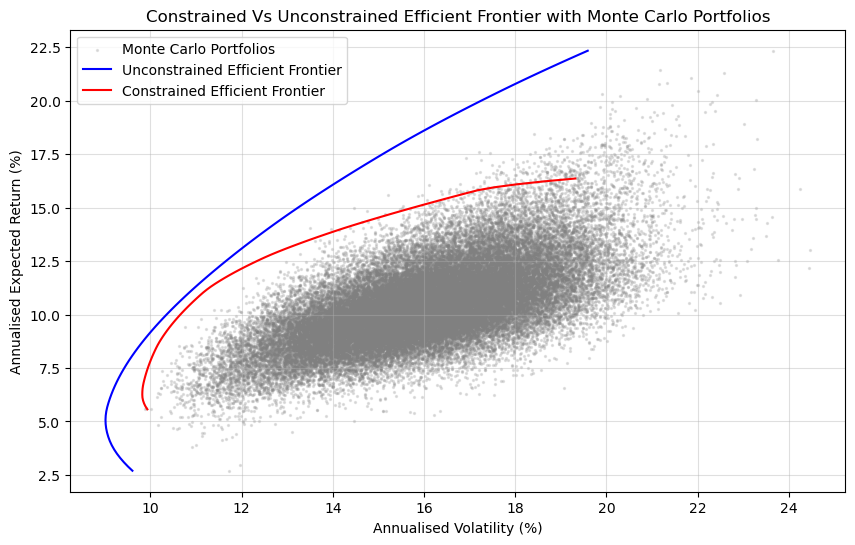

In [37]:
plt.figure(figsize = (10, 6))
plt.ylabel("Annualised Expected Return (%)")
plt.xlabel("Annualised Volatility (%)")
plt.title("Constrained Vs Unconstrained Efficient Frontier with Monte Carlo Portfolios")

# Plot Monte carlo portfolios
plt.scatter(portfolio_volatility*100, portfolio_returns*100, color = "grey", alpha = 0.2, marker = "o", s = 2, label = "Monte Carlo Portfolios")


# Plot constrained and unconstrained efficient frontiers
plt.plot(unconstrained_efficient_frontier_volatility*100, unconstrained_target_returns*100, color = "blue", label = "Unconstrained Efficient Frontier")
plt.plot(constrained_efficient_frontier_volatility*100, constrained_target_returns*100, color = "red", label = "Constrained Efficient Frontier")

plt.legend()
plt.grid(alpha = 0.4)
plt.show()

As expected, once constraints are added, the efficient frontier moves inwards as portfolios cant take as risky holdings in order to achieve higher returns.

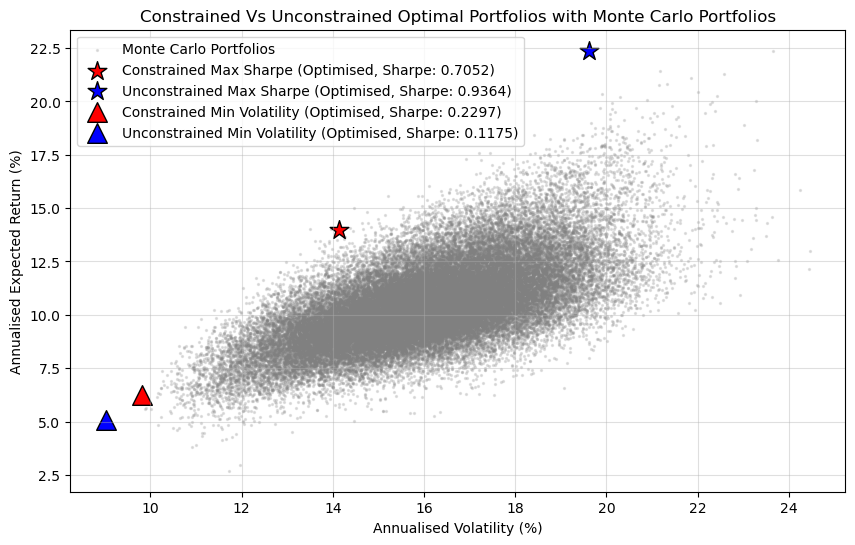

In [38]:
plt.figure(figsize = (10, 6))
plt.ylabel("Annualised Expected Return (%)")
plt.xlabel("Annualised Volatility (%)")
plt.title("Constrained Vs Unconstrained Optimal Portfolios with Monte Carlo Portfolios")

plt.scatter(portfolio_volatility*100, portfolio_returns*100, color = "grey", alpha = 0.2, marker = "o", s = 2, label = "Monte Carlo Portfolios")

# Plot constrained then unconstrained max sharpe portfolios
plt.scatter(constrained_max_sharpe_stats["Volatility"]*100, constrained_max_sharpe_stats["Return"]*100,
            color = "red", edgecolors = "black", marker = "*", label = f"Constrained Max Sharpe (Optimised, Sharpe: {constrained_max_sharpe_stats["Sharpe ratio"]:.4f})", s = 200)
plt.scatter(unconstrained_max_sharpe_stats["Volatility"]*100, unconstrained_max_sharpe_stats["Return"]*100,
            color = "blue", edgecolors = "black", marker = "*", label = f"Unconstrained Max Sharpe (Optimised, Sharpe: {unconstrained_max_sharpe_stats["Sharpe ratio"]:.4f})", s = 200)

# Plot constrained then unconstrained min volatility portfolios
plt.scatter(constrained_min_volatility_stats["Volatility"]*100, constrained_min_volatility_stats["Return"]*100,
            color = "red", edgecolors = "black", marker = "^", label = f"Constrained Min Volatility (Optimised, Sharpe: {constrained_min_volatility_stats["Sharpe ratio"]:.4f})", s = 200)
plt.scatter(unconstrained_min_volatility_stats["Volatility"]*100, unconstrained_min_volatility_stats["Return"]*100,
            color = "blue", edgecolors = "black", marker = "^", label = f"Unconstrained Min Volatility (Optimised, Sharpe: {unconstrained_min_volatility_stats["Sharpe ratio"]:.4f})", s = 200)


plt.legend()
plt.grid(alpha = 0.4)
plt.show()

## Portfolio Weightings
The next step is to take the max sharpe ratio and min volatility portfolios for the constrained and unconstrained optimisation as well as the monte carlo portfolios and compare the weightings and performance metrics of each.

In [39]:
# Create stats for mc portfolios

mc_max_sharpe_stats = portfolio_stats(optimised_weights = mc_max_sharpe_weights)
mc_min_volatility_stats = portfolio_stats(optimised_weights = mc_min_volatility_weightings)

In [40]:
performance_df = pd.DataFrame({
    "Portfolio": [
        "Monte Carlo Max Sharpe",
        "Monte Carlo Min Volatility",
        "Constrained Optimised Max Sharpe",
        "Constrained Optimised Min Volatility",
        "Unconstrained Optimised Max Sharpe",
        "Unconstrained Optimised Min Volatility"
    ],
    "Annualised Return (%)": [
        mc_max_sharpe_stats["Return"] * 100,
        mc_min_volatility_stats["Return"] * 100,
        constrained_max_sharpe_stats["Return"] * 100,
        constrained_min_volatility_stats["Return"] * 100,
        unconstrained_max_sharpe_stats["Return"] * 100,
        unconstrained_min_volatility_stats["Return"] * 100
    ],
    "Annualised Volatility (%)": [
        mc_max_sharpe_stats["Volatility"] * 100,
        mc_min_volatility_stats["Volatility"] * 100,
        constrained_max_sharpe_stats["Volatility"] * 100,
        constrained_min_volatility_stats["Volatility"] * 100,
        unconstrained_max_sharpe_stats["Volatility"] * 100,
        unconstrained_min_volatility_stats["Volatility"] * 100
    ],
    "Sharpe Ratio": [
        mc_max_sharpe_stats["Sharpe ratio"],
        mc_min_volatility_stats["Sharpe ratio"],
        constrained_max_sharpe_stats["Sharpe ratio"],
        constrained_min_volatility_stats["Sharpe ratio"],
        unconstrained_max_sharpe_stats["Sharpe ratio"],
        unconstrained_min_volatility_stats["Sharpe ratio"]]
}).round(2)

performance_df

,Portfolio,Annualised Return (%),Annualised Volatility (%),Sharpe Ratio
0,Monte Carlo Max Sharpe,21.43,21.17,0.82
1,Monte Carlo Min Volatility,5.57,9.89,0.16
2,Constrained Optimised Max Sharpe,13.96,14.13,0.71
3,Constrained Optimised Min Volatility,6.26,9.82,0.23
4,Unconstrained Optimised Max Sharpe,22.37,19.62,0.94
5,Unconstrained Optimised Min Volatility,5.06,9.01,0.12


The constrained max sharpe portfolio is clearly the best performing portfolio. While the MC and unconstrained max sharpe portfolios give the highest returns they also carry significantly higher volatility where as the constrained max sharpe has a noticeably lower volatility likely due to the constraints forcing diversification. The minimum volatility portfolios likely arent viable portfolios as they will likely be out-performed by indexes.

In [41]:
weights_df = pd.DataFrame({
    "MC Max Sharpe (%)": mc_max_sharpe_weights * 100,
    "MC Min Volatility (%)": mc_min_volatility_weightings * 100,
    "Constrained Optimised Max Sharpe (%)": constrained_max_sharpe_weights * 100,
    "Constrained Optimised Min Volatility (%)": constrained_min_vol_weights * 100,
    "Unconstrained Optimised Max Sharpe (%)": unconstrained_max_sharpe_weights * 100,
    "Unconstrained Optimised Min Volatility (%)": unconstrained_min_vol_weights * 100},
index=tickers).round(2)

weights_df

,MC Max Sharpe (%),MC Min Volatility (%),Constrained Optimised Max Sharpe (%),Constrained Optimised Min Volatility (%),Unconstrained Optimised Max Sharpe (%),Unconstrained Optimised Min Volatility (%)
AAPL,53.66,1.88,15.00,0.00,52.18,0.00
AMZN,2.37,2.61,4.32,0.00,0.00,0.00
JPM,1.84,2.10,2.46,0.00,0.00,0.23
XOM,2.84,1.97,0.00,0.00,0.00,0.00
JNJ,0.37,9.61,2.84,15.00,0.00,14.33
PG,0.68,5.29,15.00,13.29,0.00,3.58
CAT,1.31,2.93,15.00,0.33,9.75,0.81
NEE,5.02,2.59,0.00,0.00,0.00,0.00
EFA,0.90,5.35,0.00,6.18,0.00,0.00
EEM,0.47,0.79,0.00,5.19,0.00,0.00


When looking at the weights of each portfolio and comparing with the position of each asset in the graph below in terms of volatility and return there are some patterns that begin to appear. We can firstly begin to notice which assets are preferred for higher returns and which are preferred for lower volatility, ie a safer portfolio. Looking at the max sharpe portfolios, Apple is clearly the most preferred asset as it takes approxiamately 50% of both the MC and unconstrained optimal portfolio along with the full allowed allocation in the constrained portfolio. This is due to Apple having the highest return as seen in the graph below along with a relatively low volatility for how much reutrn it gives which explains its strong performance for maximising the Sharpe ratio. Gold is also a strong performer in all assets as once again it has a relatively good return for a relatively low volatility reflecting its reputation as a safe haven asset.
For the minimum volatility portfolios, the strongest performing assets are simply the assets with the lowest volatility as these assets are only impacted by asset's volatility unlike sharpe ratio portfolios which take into acount returns and volatility.

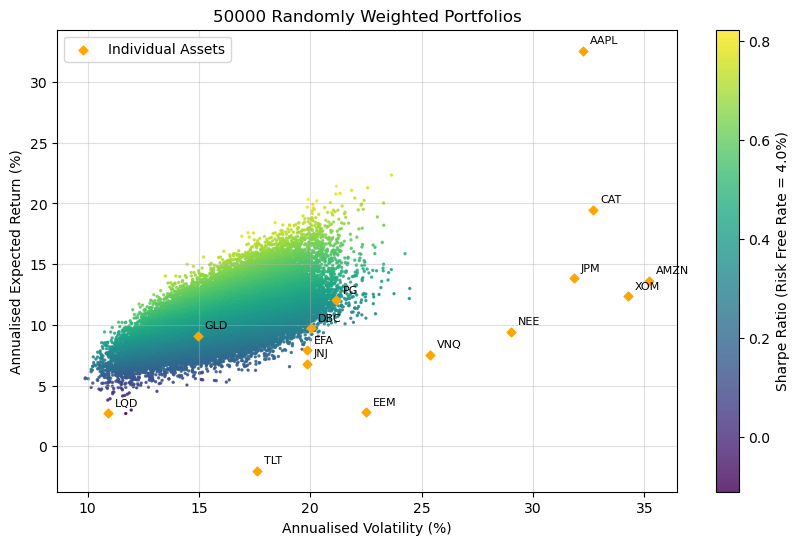

In [42]:
plt.figure(figsize = (10, 6))
plt.scatter(portfolio_volatility*100, portfolio_returns*100, alpha = 0.8, s = 2, c = portfolio_sharpe_ratios, cmap = "viridis")
plt.colorbar(label = f"Sharpe Ratio (Risk Free Rate = {risk_free_rate * 100}%)")
plt.ylabel("Annualised Expected Return (%)")
plt.xlabel("Annualised Volatility (%)")
plt.title(f"{n_weighting_sims} Randomly Weighted Portfolios")


plt.scatter(asset_annualised_volatility*100, annualised_returns*100,
            color = "orange", marker = "D", label = "Individual Assets", s = 20)

for i, ticker in enumerate(tickers):
    plt.annotate(ticker,
                 (asset_annualised_volatility[i]*100, annualised_returns[i]*100),
                 textcoords="offset points", xytext=(5, 5), fontsize=8)

plt.grid(alpha = 0.4)
plt.legend()
plt.show()

# Out of Sample Backtest 
The next step is to take the optimised weights for the constrained maximum sharpe ratio portfolio and minimum volatility portfolio. We will also use an evenly weighted portfolio and an index, which will be the S&P 500 in this case, as a benchmark.

In [43]:
# Load the chosen data for the out of sample backtest and also the index which in this case is the S&P 500

backtest_data = yf.download(tickers, start = test_start, end = test_end)
index_ticker_name = "SPY"
index_ticker = yf.Ticker(index_ticker_name)
index_data = index_ticker.history(start = test_start, end = test_end)

# Set dates for graph plotting
testing_dates = backtest_data.index

[*********************100%***********************]  15 of 15 completed


In [44]:
# Set weightings for chosen portfolio

constrained_max_sharpe_weights
constrained_min_vol_weights
even_weighting = np.ones(shape = (n_assets)) / n_assets

In [45]:
# Calculate daily log retuns for each ticker ot use for statistics
backtest_daily_log_returns = np.zeros(shape = (n_assets, len(backtest_data) - 1), dtype = float)

# Calculate simple returns for portfolio growth
backtest_daily_simple_returns = np.zeros(shape = (n_assets, len(backtest_data) - 1), dtype = float)

for i in range (n_assets):
    ticker = tickers[i]
    backtest_daily_log_returns[i] = np.log((backtest_data["Close"][ticker] / backtest_data["Close"][ticker].shift(1)).dropna())

    backtest_daily_simple_returns[i] = backtest_data["Close"][ticker].pct_change().dropna()

## Portfolio Return
The next step is to take each portfolio, hold the weights constant for the whole test period then measure the daily growth of the portfolio from the starting portfolio value

In [46]:
# Calculate the daily return for each portfolio

# Max sharpe daily return
backtest_max_sharpe_daily_return = np.array(constrained_max_sharpe_weights @ backtest_daily_simple_returns)

# Min volatility daily return
backtest_min_vol_daily_return = np.array(constrained_min_vol_weights @ backtest_daily_simple_returns)

# Even weighted portfolio daily return
backtest_even_weight_daily_return = np.array(even_weighting @ backtest_daily_simple_returns)

# Index daily return, S&P500 in this case
backtest_index_daily_simple_return = np.array(index_data["Close"].pct_change().dropna())

## Portfolio Growth Chart

In [47]:
# Set the start value of the portfolio

start_port_value = 1

# Create the growth arrays
backtest_max_sharpe_growth = start_port_value * np.cumprod(1 + backtest_max_sharpe_daily_return)
backtest_min_vol_growth = start_port_value * np.cumprod(1 + backtest_min_vol_daily_return)
backtest_even_weight_growth = start_port_value * np.cumprod(1 + backtest_even_weight_daily_return)
backtest_index_growth = start_port_value * np.cumprod(1 + backtest_index_daily_simple_return)

# Insert the starting value
backtest_max_sharpe_growth = np.insert(backtest_max_sharpe_growth, 0, start_port_value)
backtest_min_vol_growth = np.insert(backtest_min_vol_growth, 0, start_port_value)
backtest_even_weight_growth = np.insert(backtest_even_weight_growth, 0, start_port_value)
backtest_index_growth = np.insert(backtest_index_growth, 0, start_port_value)

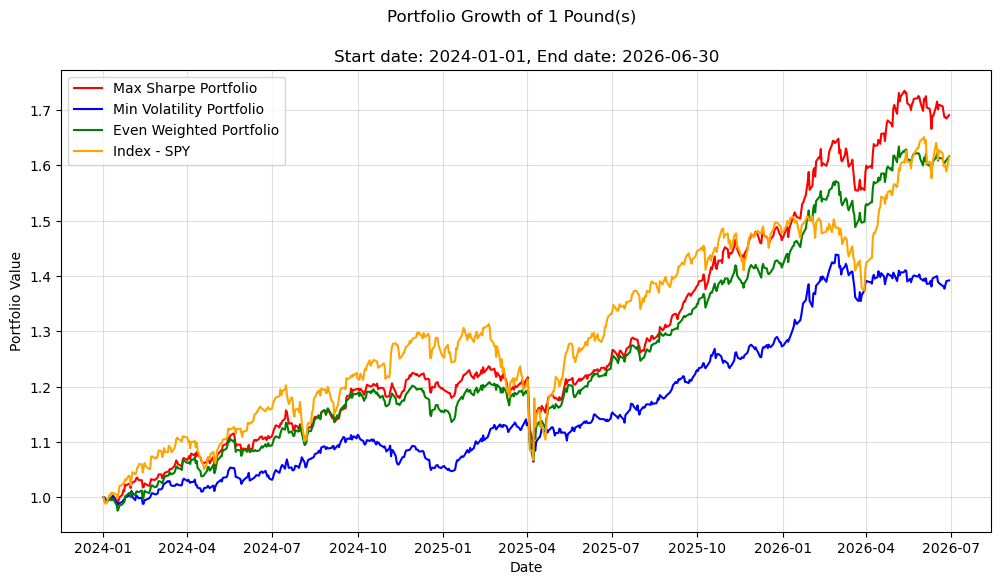

In [48]:
# Plot growth graph

plt.figure(figsize = (12,6))
plt.ylabel("Portfolio Value")
plt.xlabel("Date")
plt.suptitle(f"Portfolio Growth of {start_port_value} Pound(s)")

# Plot max sharpe portfolio
plt.plot(testing_dates, backtest_max_sharpe_growth, color = "red", label = "Max Sharpe Portfolio")

# Plot min volatility portfolio
plt.plot(testing_dates, backtest_min_vol_growth, color = "blue", label = "Min Volatility Portfolio")

# Plot even weight port
plt.plot(testing_dates, backtest_even_weight_growth, color = "green", label = "Even Weighted Portfolio")

# Plot chosen index 
plt.plot(testing_dates, backtest_index_growth, color = "orange", label = f"Index - {index_ticker_name}")

# Add caption to show dates
plt.title(f"Start date: {test_start}, End date: {test_end}")

plt.grid(alpha = 0.4)
plt.legend()
plt.show()

All the portfolio show consistent performance throught the backtest period with only 2 noticeable dips in April of both 2025 and 2026. These are both cause by Trump's actions. In April 2025 Trump announced drastic tariffs on worldwide imports to the USA. This significantly imapcted global trade, resulting in a dip in the market which is why all portfolios took a hit during that month. The dip in April 2026 was a result of Trump announcing war on Iran. This resulted in the Straight of Hormuz being closed. This impacted global trade which is why we see a slight dip in all the portfolios. However the S&P500 experienced a significantly bigger dip than the other portfolios likely due to the impact of the war on the USA specifically and the hit in confidence as a result of the war being announced. 
However, on an overall scale the portfolios behaved as expected with the max sharpe portfolio reuslting in the greatest gains while the minimum volatility portfolio gave the least returns however did have the most stable growth experiencing the smallest downturns. 
Interestingly the evenly weighted portfolio performed well and also closely with the S&P500 which can likely be explained as both of them take the same approach by having a lot of "evenly" weighted assets. 

## Portfolio Statistics (Predicted Vs Realised)

### Predicted Vs Realsied Statistics
The next step is to calculate statistics such as annualised return and volatility as well as the sharpe ratio for each portfolio during the out of sample (backtest) period and compare them to the predicted statistics from the test window.

### Maximum Sharpe Portfolio

In [49]:
# Find realised statistics for Max sharpe portfolio (annualised returns, voaltility and the Sharpe ratio)

# Find annualised returns 
realised_max_sharpe_annualised_return = ((backtest_max_sharpe_growth[-1]) ** (252 / (len(backtest_max_sharpe_growth) - 1))) - 1

# Find annualised volatility
realised_max_sharpe_annualised_volatility = np.std(backtest_max_sharpe_daily_return, ddof = 1) * np.sqrt(252)

# Find Sharpe ratio - use same risk free rate as the testing period to match the optimised ports
realised_max_sharpe_sharpe_ratio = (realised_max_sharpe_annualised_return - risk_free_rate) / realised_max_sharpe_annualised_volatility

# Find cumulative growth for future comparison
realised_max_sharpe_cumulative_return = (backtest_max_sharpe_growth[-1] / backtest_max_sharpe_growth[0]) - 1

# Find max drawdown
max_sharpe_running_peak = np.maximum.accumulate(backtest_max_sharpe_growth)
max_sharpe_drawdown = (
    backtest_max_sharpe_growth - max_sharpe_running_peak
) / max_sharpe_running_peak
max_sharpe_max_drawdown = max_sharpe_drawdown.min()

In [50]:
# Plot a table to compare the realised and predicted portfolio stats for the maximum Sharpe portfolio

max_sharpe_port_stats_compare_df = pd.DataFrame({
    "Metric":[
        "Annualised Returns",
        "Annualised Volatility",
        "Sharpe Ratio"
    ],
    "Predicted (%)":[
        constrained_max_sharpe_stats["Return"] * 100,
        constrained_max_sharpe_stats["Volatility"] * 100,
        constrained_max_sharpe_stats["Sharpe ratio"]
    ],
    "Realised (%)":[
        realised_max_sharpe_annualised_return * 100,
        realised_max_sharpe_annualised_volatility * 100,
        realised_max_sharpe_sharpe_ratio
    ],
    "Difference":[
        realised_max_sharpe_annualised_return * 100 - constrained_max_sharpe_stats["Return"] * 100,
        realised_max_sharpe_annualised_volatility * 100 - constrained_max_sharpe_stats["Volatility"] * 100,
        realised_max_sharpe_sharpe_ratio - constrained_max_sharpe_stats["Sharpe ratio"]
    ]
}).round(2)

print("Maximum Sharpe Portfolio Statistics")
display(max_sharpe_port_stats_compare_df)
print(f"Predicted period start: {train_start}, Predicted period end: {train_end}")
print(f"Realised period start: {test_start}, Realised period end: {test_end}")

Maximum Sharpe Portfolio Statistics


,Metric,Predicted (%),Realised (%),Difference
0,Annualised Returns,13.96,23.68,9.71
1,Annualised Volatility,14.13,11.08,-3.05
2,Sharpe Ratio,0.71,1.78,1.07


Predicted period start: 2019-01-01, Predicted period end: 2023-12-31
Realised period start: 2024-01-01, Realised period end: 2026-06-30


The Max sharpe ratio portfolio performed significantly better in terms of returns during the test period compared the training period. The training period took place over covid where global production significantly fell resulting in lower returns. Whereas the testing period did not include any global shocks resulting in strong returns. Interestingly while returns were drastically different volatility was only slughtly lower in the period without the global shock. The difference in sharpe ratio is heavily driven by the large difference in returns.

### Minimum Volatility Portfolio

In [51]:
# Find realised statistics for min volatility portfolio (annualised returns, voaltility and the Sharpe ratio)

# Find annualised returns
realised_min_vol_annualised_return = ((backtest_min_vol_growth[-1]) ** (252 / (len(backtest_min_vol_growth) - 1))) - 1

# Find annualised volatility
realised_min_vol_annualised_volatility = np.std(backtest_min_vol_daily_return, ddof = 1) * np.sqrt(252)

# Find Sharpe ratio - use same risk free rate as the testing period to match the optimised ports
realised_min_vol_sharpe_ratio = (realised_min_vol_annualised_return - risk_free_rate) / realised_min_vol_annualised_volatility

# Find cumulative growth for future comparison
realised_min_vol_cumulative_return = (backtest_min_vol_growth[-1] / backtest_min_vol_growth[0]) - 1

# Find max drawdown 
min_vol_running_peak = np.maximum.accumulate(backtest_min_vol_growth)
min_vol_drawdown = (
    backtest_min_vol_growth - min_vol_running_peak
) / min_vol_running_peak
min_vol_max_drawdown = min_vol_drawdown.min()

In [52]:
# Plot a table to compare the realised and predicted portfolio stats for the minimum volatility portfolio

min_vol_port_stats_compare_df = pd.DataFrame({
    "Metric":[
        "Annualised Returns",
        "Annualised Volatility",
        "Sharpe Ratio"
    ],
    "Predicted (%)":[
        constrained_min_volatility_stats["Return"] * 100,
        constrained_min_volatility_stats["Volatility"] * 100,
        constrained_min_volatility_stats["Sharpe ratio"]
    ],
    "Realised (%)":[
        realised_min_vol_annualised_return * 100,
        realised_min_vol_annualised_volatility * 100,
        realised_min_vol_sharpe_ratio
    ],
    "Difference":[
    realised_min_vol_annualised_return * 100 - constrained_min_volatility_stats["Return"] * 100,
    realised_min_vol_annualised_volatility * 100 - constrained_min_volatility_stats["Volatility"] * 100,
    realised_min_vol_sharpe_ratio - constrained_min_volatility_stats["Sharpe ratio"]
]
}).round(2)

print("Minimum Volatility Portfolio statistics")
display(min_vol_port_stats_compare_df)
print(f"Predicted period start: {train_start}, Predicted period end: {train_end}")
print(f"Realised period start: {test_start}, Realised period end: {test_end}")

Minimum Volatility Portfolio statistics


,Metric,Predicted (%),Realised (%),Difference
0,Annualised Returns,6.26,14.33,8.07
1,Annualised Volatility,9.82,8.29,-1.53
2,Sharpe Ratio,0.23,1.25,1.02


Predicted period start: 2019-01-01, Predicted period end: 2023-12-31
Realised period start: 2024-01-01, Realised period end: 2026-06-30


Once again we see the realised returns are much higher than the predicted returns once again due to not including the global shock of the covid lockdowns. The difference in volatility is even smaller in the minimum volatility portfolio likely due to the fact the portfolio aims to minimise volatility and lean towards safer assets which likely werent as heavily impacted by covid compared to the max sharpe portfolio assets.

## Portfolio Performance Comparison
Finally, compare the performance of each of the 3 portoflio and the indexes performance during the backtest period

In [53]:
# Calculate statistics for the index and even weighted portfolio

# Evenly weighted portfolio
realised_even_weight_annualised_return = ((backtest_even_weight_growth[-1]) ** (252 / (len(backtest_even_weight_growth) - 1))) - 1
realised_even_weight_annualised_volatility = np.std(backtest_even_weight_daily_return, ddof = 1) * np.sqrt(252)
realised_even_weight_cumulative_return = (backtest_even_weight_growth[-1] / backtest_even_weight_growth[0]) - 1
realised_even_weight_sharpe_ratio = (realised_even_weight_annualised_return - risk_free_rate) / realised_even_weight_annualised_volatility
realised_evenly_weighted_running_peak = np.maximum.accumulate(backtest_even_weight_growth)
realised_evenly_weighted_drawdown = (
    backtest_even_weight_growth - realised_evenly_weighted_running_peak
) / realised_evenly_weighted_running_peak
even_weight_max_drawdown = realised_evenly_weighted_drawdown.min()

# Index - S&P 500 for this project
realised_index_annualised_return = ((backtest_index_growth[-1]) ** (252 / (len(backtest_index_growth) - 1))) - 1
realised_index_annualised_volatility = np.std(backtest_index_daily_simple_return, ddof = 1) * np.sqrt(252)
realised_index_cumulative_return = (backtest_index_growth[-1] / backtest_index_growth[0]) - 1
realised_index_sharpe_ratio = (realised_index_annualised_return - risk_free_rate) / realised_index_annualised_volatility
realised_index_running_peak = np.maximum.accumulate(backtest_index_growth)
realised_index_drawdown = (
    backtest_index_growth - realised_index_running_peak
) / realised_index_running_peak
index_max_drawdown = realised_index_drawdown.min()

In [54]:
# Create table to compare

backtest_portfolio_comparison_df = pd.DataFrame({
    "Metric":[
        "Annualised Return (%)",
        "Annualised Volatility (%)",
        "Cumulative Return (%)",
        "Sharpe Ratio",
        "Max Drawdown (%)"
    ],
    "Max Sharpe Portfolio":[
        realised_max_sharpe_annualised_return * 100,
        realised_max_sharpe_annualised_volatility * 100,
        realised_max_sharpe_cumulative_return * 100,
        realised_max_sharpe_sharpe_ratio,
        max_sharpe_max_drawdown * 100
    ],
    "Min Volatility Portfolio":[
        realised_min_vol_annualised_return * 100,
        realised_min_vol_annualised_volatility * 100,
        realised_min_vol_cumulative_return * 100,
        realised_min_vol_sharpe_ratio,
        min_vol_max_drawdown * 100
    ],
    "Evenly Weighted Portfolio":[
        realised_even_weight_annualised_return * 100,
        realised_even_weight_annualised_volatility * 100,
        realised_even_weight_cumulative_return * 100,
        realised_even_weight_sharpe_ratio,
        even_weight_max_drawdown * 100
    ],
    f"Index - {index_ticker_name}":[
        realised_index_annualised_return * 100,
        realised_index_annualised_volatility * 100,
        realised_index_cumulative_return * 100,
        realised_index_sharpe_ratio,
        index_max_drawdown * 100]      
}).round(2)

print("Portfolio performance during backtest period")
print(f"Start date: {test_start}, End date: {test_end}")
display(backtest_portfolio_comparison_df)

Portfolio performance during backtest period
Start date: 2024-01-01, End date: 2026-06-30


,Metric,Max Sharpe Portfolio,Min Volatility Portfolio,Evenly Weighted Portfolio,Index - SPY
0,Annualised Return (%),23.68,14.33,21.44,21.40
1,Annualised Volatility (%),11.08,8.29,10.59,15.97
2,Cumulative Return (%),69.10,39.23,61.65,61.51
3,Sharpe Ratio,1.78,1.25,1.65,1.09
4,Max Drawdown (%),-12.51,-6.71,-11.62,-18.76


Over the out-of-sample period from 1 January 2024 to 30 June 2026, all four portfolios delivered strong returns, and the optimised portfolios performed well on a risk-adjusted basis. The maximum Sharpe portfolio produced the highest annualised return (23.68%) and cumulative return (69.10%), with a Sharpe ratio of 1.78 against 1.65 for the evenly weighted portfolio and 1.09 for the S&P 500 (SPY). The minimum volatility portfolio achieved its objective, recording the lowest annualised volatility (8.29%) and the shallowest maximum drawdown (-6.71%), at the cost of a lower return (14.33%), although its Sharpe ratio of 1.25 still exceeded the index. The index was the riskiest portfolio, with volatility of 15.97% and a maximum drawdown of -18.76%, yet its return of 21.40% was almost identical to the evenly weighted portfolio's 21.44%, so the diversified portfolios achieved similar returns with considerably less risk. 

The margin between the maximum Sharpe and evenly weighted portfolios is modest (a Sharpe difference of 0.13), which suggests that optimisation added some value but that simple diversification captured most of the benefit. Realised results were also better than the in-sample predictions for the constrained portfolios, with higher returns and lower volatility than the optimiser forecast, so there is no sign of the out-of-sample deterioration that estimation error would typically cause. This is most likely because the test window was a favourable market, and the result should be treated as illustrative since it covers a single 2.5-year period, assumes daily rebalancing to constant weights, and ignores transaction costs. Sharpe ratios use a 4% risk-free rate.

# Conditional Value at Risk (CVaR) Extension
One of the main criticisms of Markowitz optimisation is that it measures portfolio risk using the portfolios volatility but that treats both positive and negative volatility equally. However, it's clear that we would prefer positive volatility rather than negative volatility. CVaR does this by only looking at the negative volatility.
CVaR asks the question what is the average loss of the 5% worst days of the portfolio.

In [55]:
# Begin by finding the CVaR for the max sharpe and min volatility portfolio using a 95% confidence level to look at approx 60 training days
# Find simple daily returns of both portfolios during the training period
# Training period asset simple returns

training_daily_simple_returns = np.zeros(shape = (n_assets, len(training_data) - 1), dtype = float)

for i in range (n_assets):
    ticker = tickers[i]
    training_daily_simple_returns[i] = training_data["Close"][ticker].pct_change().dropna()
    
# Max sharpe daily return during training period
training_max_sharpe_daily_return = np.array(constrained_max_sharpe_weights @ training_daily_simple_returns)

# Min volatility daily return during training period
training_min_vol_daily_return = np.array(constrained_min_vol_weights @ training_daily_simple_returns)

In [56]:
# Find the CVaR for both max sharpe, min vol portfolios during the training period at 5% confidence level

confidence_level = 95

# Find the VaR threshold for each portfolio
max_sharpe_var = np.percentile(training_max_sharpe_daily_return, 100 - confidence_level)
min_volatility_var = np.percentile(training_min_vol_daily_return, 100 - confidence_level)

# Next find the CVaR by filtering to the percentile threshold and then averaging
max_sharpe_cvar = np.mean(training_max_sharpe_daily_return[training_max_sharpe_daily_return <= max_sharpe_var])
min_volatility_cvar = np.mean(training_min_vol_daily_return[training_min_vol_daily_return <= min_volatility_var])

## Minimum CVaR Optimal Portfolio
Once again we can use Scipy Optimize to find the portfolio which minimises CVaR

In [57]:
# Define new CVaR objective function that Scipy can minimise

def cvar_stat(optimised_weights, chosen_stock_data, optimisation_confidence_level = 95):

    chosen_data_test_daily_simple_returns = np.zeros(shape = (n_assets, len(chosen_stock_data) - 1), dtype = float)
    
    for i in range (n_assets):
        ticker = tickers[i]
        chosen_data_test_daily_simple_returns[i] = chosen_stock_data["Close"][ticker].pct_change().dropna()
    
    optimised_weights = np.array(optimised_weights)
    portfolio_daily_returns = optimised_weights @ chosen_data_test_daily_simple_returns

    optimisation_var = np.percentile(portfolio_daily_returns, 100 - optimisation_confidence_level)

    optimisation_cvar = np.mean(portfolio_daily_returns[portfolio_daily_returns <= optimisation_var])

    return {"abs": abs(optimisation_cvar), "raw": optimisation_cvar}

def minimize_cvar(optimised_weights, chosen_stock_data = training_data):
    return cvar_stat(optimised_weights, chosen_stock_data = training_data)["abs"]

In [58]:
# Define remaining constraints, boudns and initial guess

# Set constraints so that sum of weights equal 1
constraints = {"type":"eq", "fun": lambda x: np.sum(x) - 1}

# Set bounds so that no asset can be short sold or more than 15% of the portfolio is held in 1 asset
bounds = [(0, 0.15)] * n_assets

# Set initial guess for equal weighting
initial_guess = n_assets * [1/n_assets]

In [59]:
# Minimise CVaR using Scipy optimise

optimised_cvar = minimize(minimize_cvar,
                         initial_guess,
                         method = "SLSQP",
                         constraints = constraints,
                         bounds = bounds)

optimised_cvar_weights = optimised_cvar["x"]
optimised_cvar_test_stats = portfolio_stats(optimised_weights = optimised_cvar_weights)

In [60]:
# Create a comparison table to compare portfolios

test_period_cvar_port_comparison_df = pd.DataFrame({
    "Metric":[
        "Annualised Return (%)",
        "Annualised Volatility (%)",
        "Sharpe Ratio",
        "CVaR (%)"
    ],
    "Max Sharpe Portfolio":[
    constrained_max_sharpe_stats["Return"]*100,
    constrained_max_sharpe_stats["Volatility"]*100,
    constrained_max_sharpe_stats["Sharpe ratio"],
    cvar_stat(optimised_weights = constrained_max_sharpe_weights, chosen_stock_data = training_data)["raw"]*100
    ],
    "Min Volatility Portfolio":[
        constrained_min_volatility_stats["Return"]*100,
        constrained_min_volatility_stats["Volatility"]*100,
        constrained_min_volatility_stats["Sharpe ratio"],
        cvar_stat(optimised_weights = constrained_min_vol_weights, chosen_stock_data = training_data)["raw"]*100
    ],
    "Optimised CVaR Portfolio":[
    optimised_cvar_test_stats["Return"]*100,
    optimised_cvar_test_stats["Volatility"]*100,
    optimised_cvar_test_stats["Sharpe ratio"],
    cvar_stat(optimised_weights = optimised_cvar_weights, chosen_stock_data = training_data)["raw"]*100
    ]
}).round(2)

In [61]:
# Display CVaR test period portfolio statistics

print("Portfolio training period statistics including CVaR")
display(test_period_cvar_port_comparison_df)

Portfolio training period statistics including CVaR


,Metric,Max Sharpe Portfolio,Min Volatility Portfolio,Optimised CVaR Portfolio
0,Annualised Return (%),13.96,6.26,6.27
1,Annualised Volatility (%),14.13,9.82,9.85
2,Sharpe Ratio,0.71,0.23,0.23
3,CVaR (%),-2.08,-1.39,-1.39


We can see that the minimum volatility and minimum CVaR portfolio performed almost identically. As the CVaR portfolio was optimised during the training period that contained COVID, most the volatility during this period was likely negative therefore the volatility is mostly reflective of negative volatility which is what CVaR shows therefore resulting in very similar results. However, comparing the CVaR with the max sharpe portfolio we can see that optimising volatility and CVaR does give some benefit when it comes to minimising the worst days of loss.

## Backtest Period and daily growth

In [62]:
# Create backtest period statistics for optimised CVaR portfolio

backtest_min_cvar_daily_return = np.array(optimised_cvar_weights @ backtest_daily_simple_returns)

# Growth chart
backtest_min_cvar_growth = start_port_value * np.cumprod(1 + backtest_min_cvar_daily_return)
backtest_min_cvar_growth = np.insert(backtest_min_cvar_growth, 0, start_port_value)

realised_min_cvar_annualised_return = ((backtest_min_cvar_growth[-1]) ** (252 / (len(backtest_min_cvar_growth) - 1))) - 1
realised_min_cvar_annualised_volatility = np.std(backtest_min_cvar_daily_return, ddof = 1) * np.sqrt(252)
realised_min_cvar_sharpe_ratio = (realised_min_cvar_annualised_return - risk_free_rate) / realised_min_cvar_annualised_volatility
realised_min_cvar_cumulative_return = (backtest_min_cvar_growth[-1] / backtest_min_cvar_growth[0]) - 1

# Find max drawdown
min_cvar_running_peak = np.maximum.accumulate(backtest_min_cvar_growth)
min_cvar_drawdown = (
    backtest_min_cvar_growth - min_cvar_running_peak
) / min_cvar_running_peak
min_cvar_max_drawdown = min_cvar_drawdown.min()

# Index backtest CVaR
index_var = np.percentile(backtest_index_daily_simple_return, 100 - confidence_level)
index_cvar = np.mean(backtest_index_daily_simple_return[backtest_index_daily_simple_return <= index_var])

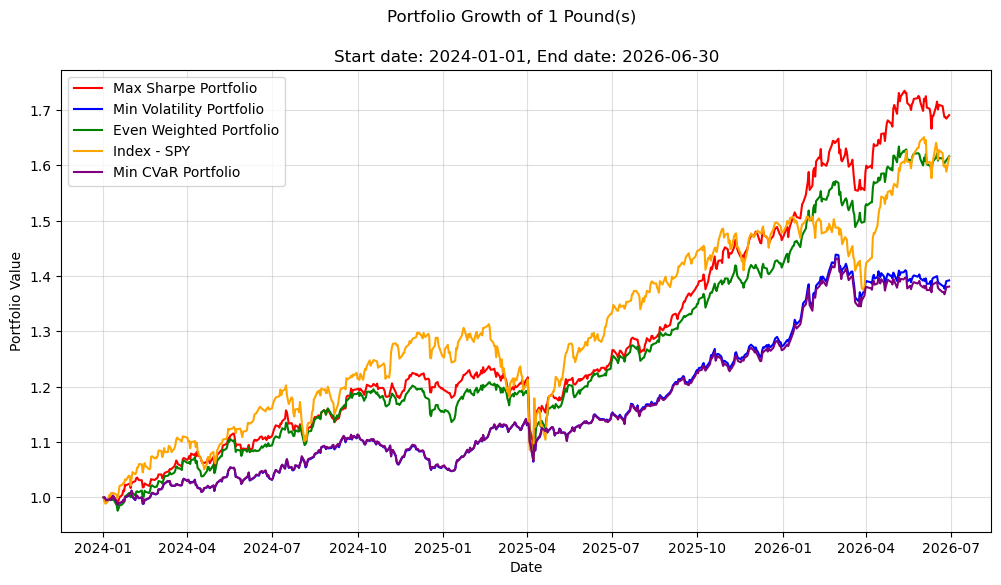

In [63]:
# Plot growth chart again with CVaR portfolio added

plt.figure(figsize = (12,6))
plt.ylabel("Portfolio Value")
plt.xlabel("Date")
plt.suptitle(f"Portfolio Growth of {start_port_value} Pound(s)")

# Plot max sharpe portfolio
plt.plot(testing_dates, backtest_max_sharpe_growth, color = "red", label = "Max Sharpe Portfolio")

# Plot min volatility portfolio
plt.plot(testing_dates, backtest_min_vol_growth, color = "blue", label = "Min Volatility Portfolio")

# Plot even weight port
plt.plot(testing_dates, backtest_even_weight_growth, color = "green", label = "Even Weighted Portfolio")

# Plot chosen index 
plt.plot(testing_dates, backtest_index_growth, color = "orange", label = f"Index - {index_ticker_name}")

# Plot min CVaR portfolio
plt.plot(testing_dates, backtest_min_cvar_growth, color = "purple", label = "Min CVaR Portfolio")

# Add caption to show dates
plt.title(f"Start date: {test_start}, End date: {test_end}")

plt.grid(alpha = 0.4)
plt.legend()
plt.show()

In [64]:
# Create another table with the same statistics but during the test period also including evenly weighted portfolio and the chosen index

backtest_portfolio_cvar_comparison_df = pd.DataFrame({
    "Metric":[
        "Annualised Return (%)",
        "Annualised Volatility (%)",
        "Cumulative Return (%)",
        "Sharpe Ratio",
        "Max Drawdown (%)",
        "CVaR (%)"
    ],
    "Max Sharpe Portfolio":[
        realised_max_sharpe_annualised_return * 100,
        realised_max_sharpe_annualised_volatility * 100,
        realised_max_sharpe_cumulative_return * 100,
        realised_max_sharpe_sharpe_ratio,
        max_sharpe_max_drawdown * 100,
        cvar_stat(optimised_weights = constrained_max_sharpe_weights, chosen_stock_data = test_data)["raw"]*100
    ],
    "Min Volatility Portfolio":[
        realised_min_vol_annualised_return * 100,
        realised_min_vol_annualised_volatility * 100,
        realised_min_vol_cumulative_return * 100,
        realised_min_vol_sharpe_ratio,
        min_vol_max_drawdown * 100,
        cvar_stat(optimised_weights = constrained_min_vol_weights, chosen_stock_data = test_data)["raw"]*100

    ],
    "Evenly Weighted Portfolio":[
        realised_even_weight_annualised_return * 100,
        realised_even_weight_annualised_volatility * 100,
        realised_even_weight_cumulative_return * 100,
        realised_even_weight_sharpe_ratio,
        even_weight_max_drawdown * 100,
        cvar_stat(optimised_weights = even_weighting, chosen_stock_data = test_data)["raw"]*100
    ],
    f"Index - {index_ticker_name}":[
        realised_index_annualised_return * 100,
        realised_index_annualised_volatility * 100,
        realised_index_cumulative_return * 100,
        realised_index_sharpe_ratio,
        index_max_drawdown * 100,
        index_cvar * 100
    ],
    "Min CVaR Portfolio":[
        realised_min_cvar_annualised_return * 100,
        realised_min_cvar_annualised_volatility * 100,
        realised_min_cvar_cumulative_return * 100,
        realised_min_cvar_sharpe_ratio,
        min_cvar_max_drawdown * 100,
        cvar_stat(optimised_weights = optimised_cvar_weights, chosen_stock_data = test_data)["raw"] * 100
    ]
}).round(2)

print("Backtest period portfolio comparison including CVaR")
display(backtest_portfolio_cvar_comparison_df)

Backtest period portfolio comparison including CVaR


,Metric,Max Sharpe Portfolio,Min Volatility Portfolio,Evenly Weighted Portfolio,Index - SPY,Min CVaR Portfolio
0,Annualised Return (%),23.68,14.33,21.44,21.40,13.95
1,Annualised Volatility (%),11.08,8.29,10.59,15.97,8.32
2,Cumulative Return (%),69.10,39.23,61.65,61.51,38.12
3,Sharpe Ratio,1.78,1.25,1.65,1.09,1.20
4,Max Drawdown (%),-12.51,-6.71,-11.62,-18.76,-6.62
5,CVaR (%),-1.50,-1.21,-1.49,-2.26,-1.21


Adding the minimum CVaR portfolio changes the picture very little. Its out-of-sample results are almost identical to the minimum volatility portfolio: annualised volatility of 8.32% against 8.29%, a CVaR of -1.21% for both, and a maximum drawdown of -6.62% against -6.71%. It returned slightly less (13.95% against 14.33% annualised) and so had a slightly lower Sharpe ratio (1.20 against 1.25). This similarity suggests that, for this asset universe and constraint set, minimising variance and minimising expected tail loss select very similar portfolios, which is what we would expect if returns are close to normally distributed. The tail-risk comparison across all portfolios is clear. The two low-risk portfolios had the smallest average loss in the worst days (-1.21%), the maximum Sharpe and evenly weighted portfolios were close to each other (-1.50% and -1.49%), and the S&P 500 had the largest tail loss (-2.26%), roughly double that of the low-risk portfolios. The maximum Sharpe portfolio therefore took on more tail risk than the minimum risk portfolios, but this was compensated by a higher return and the highest Sharpe ratio (1.78). Using CVaR as the risk measure did not clearly improve tail protection out of sample compared with minimum volatility, so in this case the added complexity of CVaR optimisation brought little benefit over mean-variance optimisation. These results come from a single test window of about 2.5 years, and the CVaR figures rest on only the worst 5% of daily returns (roughly 30 days), so the small differences between portfolios should not be treated as meaningful.

In [65]:
# Finally compare the weights of the portfolios

cvar_weights_df = pd.DataFrame({
    "Max Sharpe Ratio Portfolio": constrained_max_sharpe_weights * 100,
    "Min Volatility Portfolio": constrained_min_vol_weights * 100,
    "Optimised CVaR Portfolio": optimised_cvar_weights * 100},
index=tickers).round(2)

cvar_weights_df

,Max Sharpe Ratio Portfolio,Min Volatility Portfolio,Optimised CVaR Portfolio
AAPL,15.00,0.00,0.00
AMZN,4.32,0.00,0.00
JPM,2.46,0.00,0.00
XOM,0.00,0.00,0.00
JNJ,2.84,15.00,15.00
PG,15.00,13.29,15.00
CAT,15.00,0.33,0.00
NEE,0.00,0.00,0.00
EFA,0.00,6.18,5.23
EEM,0.00,5.19,5.33


When looking at weightings we can see that the max sharpe ratio portfolio avoids assets with low volatility and returns while the minimum volatility and CVaR portfolio favour them while there are a few assets such as LQD, GLD and DBC have the full 15% in all portfolios. All these assets give a good, even balance between volatility and return.